In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
sys.path.append(os.getcwd())
from common import *
import numpy as np, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

df = load_clean()
train, test = blocked_split(df)
print(len(df), len(train), len(test))

X_test, y_test = test[FEATURES], test[TARGET]
names = ["DecisionTree", "RandomForest", "SVM_RBF"]
models = {n: joblib.load(f"models/{n}.joblib") for n in names}

pred = {n: m.predict(X_test) for n, m in models.items()}
for n in names:
    print(n, "accuracy:", accuracy_score(y_test, pred[n]))

saved = pd.read_csv("models/predictions_test.csv")
print("row_index matches:", (saved["row_index"].values == test.index.values).all())
for n in names:
    print(n, "matches saved:", (saved[n].values == pred[n]).all())

134019 107218 26801
DecisionTree accuracy: 1.0
RandomForest accuracy: 1.0
SVM_RBF accuracy: 1.0
row_index matches: True
DecisionTree matches saved: True
RandomForest matches saved: True
SVM_RBF matches saved: True


========== DecisionTree ==========
              precision    recall  f1-score   support

          NF     1.0000    1.0000    1.0000      4467
          LG     1.0000    1.0000    1.0000      4467
          LL     1.0000    1.0000    1.0000      4466
         LLG     1.0000    1.0000    1.0000      4467
         LLL     1.0000    1.0000    1.0000      4467
        LLLG     1.0000    1.0000    1.0000      4467

    accuracy                         1.0000     26801
   macro avg     1.0000    1.0000    1.0000     26801
weighted avg     1.0000    1.0000    1.0000     26801



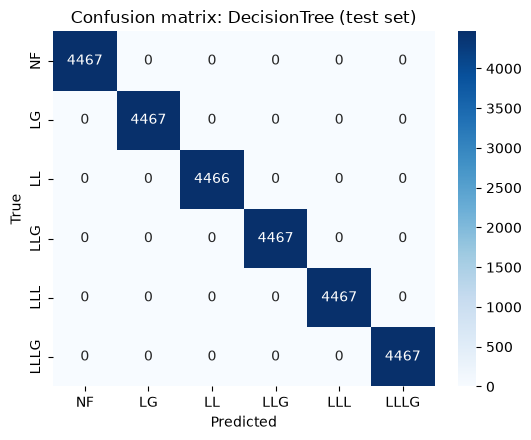

========== RandomForest ==========
              precision    recall  f1-score   support

          NF     1.0000    1.0000    1.0000      4467
          LG     1.0000    1.0000    1.0000      4467
          LL     1.0000    1.0000    1.0000      4466
         LLG     1.0000    1.0000    1.0000      4467
         LLL     1.0000    1.0000    1.0000      4467
        LLLG     1.0000    1.0000    1.0000      4467

    accuracy                         1.0000     26801
   macro avg     1.0000    1.0000    1.0000     26801
weighted avg     1.0000    1.0000    1.0000     26801



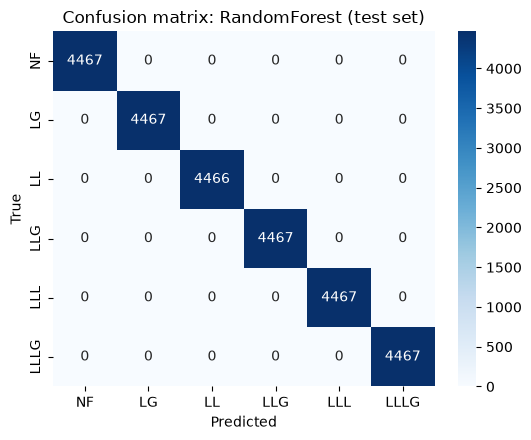

========== SVM_RBF ==========
              precision    recall  f1-score   support

          NF     1.0000    1.0000    1.0000      4467
          LG     1.0000    1.0000    1.0000      4467
          LL     1.0000    1.0000    1.0000      4466
         LLG     1.0000    1.0000    1.0000      4467
         LLL     1.0000    1.0000    1.0000      4467
        LLLG     1.0000    1.0000    1.0000      4467

    accuracy                         1.0000     26801
   macro avg     1.0000    1.0000    1.0000     26801
weighted avg     1.0000    1.0000    1.0000     26801



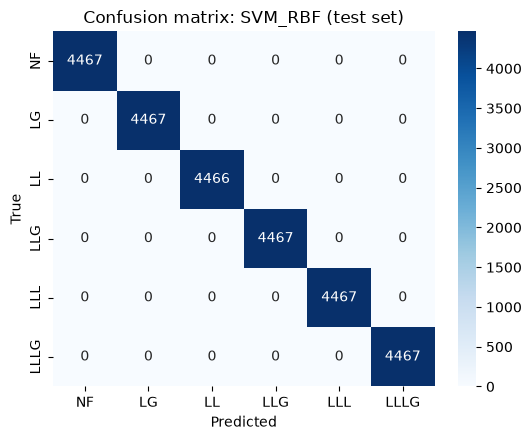

          model  accuracy  macro_F1  n_errors
0  DecisionTree       1.0       1.0         0
1  RandomForest       1.0       1.0         0
2       SVM_RBF       1.0       1.0         0
fault_types
LG      4467
LLG     4467
LLL     4467
LLLG    4467
NF      4467
LL      4466
Name: count, dtype: int64


In [2]:
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

rows = []
for n in names:
    print("=" * 10, n, "=" * 10)
    print(classification_report(y_test, pred[n], labels=CLASSES, digits=4))
    rows.append({
        "model": n,
        "accuracy": accuracy_score(y_test, pred[n]),
        "macro_F1": f1_score(y_test, pred[n], labels=CLASSES, average="macro"),
        "n_errors": int((y_test.values != pred[n]).sum()),
    })
    cm = confusion_matrix(y_test, pred[n], labels=CLASSES)
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix: {n} (test set)")
    plt.tight_layout()
    plt.savefig(f"figures/cm_{n}.png", dpi=200)
    plt.show()

comparison = pd.DataFrame(rows)
comparison.to_csv("results/model_comparison.csv", index=False)
print(comparison)
print(y_test.value_counts())

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
sys.path.append(os.getcwd())
from common import *
import numpy as np, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

df = load_clean()
train, test = blocked_split(df)
X_test, y_test = test[FEATURES], test[TARGET]
names = ["DecisionTree", "RandomForest", "SVM_RBF"]
models = {n: joblib.load(f"models/{n}.joblib") for n in names}
pred = {n: m.predict(X_test) for n, m in models.items()}
for n in names:
    print(n, "accuracy:", accuracy_score(y_test, pred[n]))

DecisionTree accuracy: 1.0
RandomForest accuracy: 1.0
SVM_RBF accuracy: 1.0


In [2]:
import time
std = train[FEATURES].std().values
levels = [0, 0.05, 0.10, 0.20, 0.50]
N_REPEATS = 3
rng = np.random.default_rng(RANDOM_STATE)

rows = []
for lv in levels:
    for n in names:
        t0 = time.time()
        accs, f1s = [], []
        for r in range(1 if lv == 0 else N_REPEATS):
            Xn = X_test + rng.normal(0, 1, X_test.shape) * std * lv
            p = models[n].predict(Xn)
            accs.append(accuracy_score(y_test, p))
            f1s.append(f1_score(y_test, p, labels=CLASSES, average="macro"))
        rows.append({"noise_pct": int(lv * 100), "model": n,
                     "accuracy": np.mean(accs), "macro_F1": np.mean(f1s)})
        print(f"noise {int(lv*100)}% {n} done in {time.time()-t0:.0f}s", flush=True)
noise = pd.DataFrame(rows)
noise.to_csv("results/noise_test.csv", index=False)
print(noise.pivot(index="noise_pct", columns="model", values="accuracy").round(4))

noise 0% DecisionTree done in 1s
noise 0% RandomForest done in 1s
noise 0% SVM_RBF done in 64s
noise 5% DecisionTree done in 5s
noise 5% RandomForest done in 14s
noise 5% SVM_RBF done in 193s
noise 10% DecisionTree done in 3s
noise 10% RandomForest done in 5s
noise 10% SVM_RBF done in 175s
noise 20% DecisionTree done in 2s
noise 20% RandomForest done in 3s
noise 20% SVM_RBF done in 91s
noise 50% DecisionTree done in 2s
noise 50% RandomForest done in 11s
noise 50% SVM_RBF done in 127s
model      DecisionTree  RandomForest  SVM_RBF
noise_pct                                     
0                1.0000        1.0000   1.0000
5                0.9298        0.9564   1.0000
10               0.8535        0.9172   0.9912
20               0.7407        0.8306   0.9367
50               0.5048        0.6163   0.7465


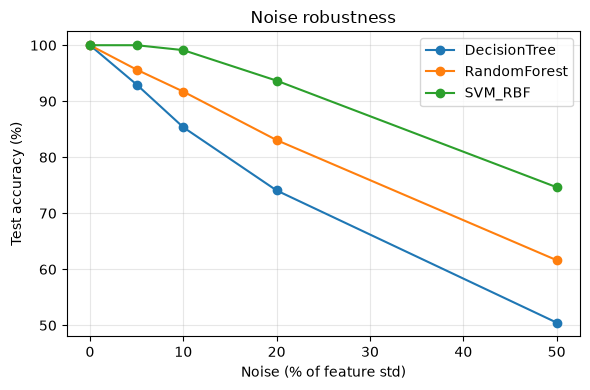

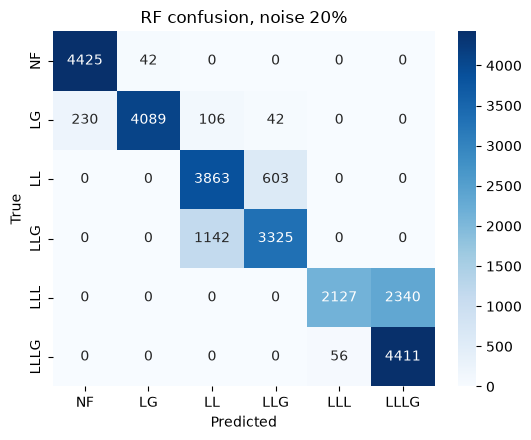

Noise 20% top confusions (true, predicted, count): [('LLL', 'LLLG', 2340), ('LLG', 'LL', 1142), ('LL', 'LLG', 603), ('LG', 'NF', 230), ('LG', 'LL', 106), ('LLLG', 'LLL', 56)]


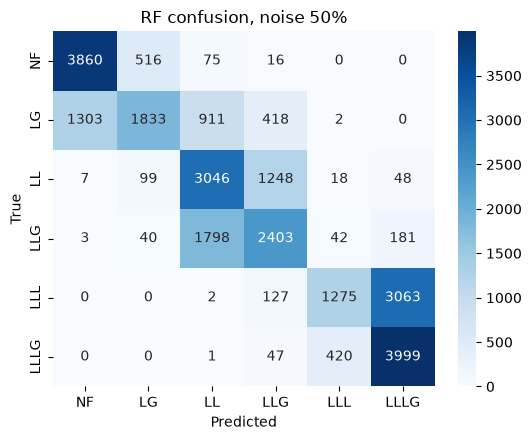

Noise 50% top confusions (true, predicted, count): [('LLL', 'LLLG', 3063), ('LLG', 'LL', 1798), ('LG', 'NF', 1303), ('LL', 'LLG', 1248), ('LG', 'LL', 911), ('NF', 'LG', 516)]


In [3]:
plt.figure(figsize=(6, 4))
for n in names:
    d = noise[noise.model == n]
    plt.plot(d.noise_pct, d.accuracy * 100, marker="o", label=n)
plt.xlabel("Noise (% of feature std)"); plt.ylabel("Test accuracy (%)")
plt.title("Noise robustness"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("figures/noise_robustness.png", dpi=200); plt.show()

for lv in [0.20, 0.50]:
    Xn = X_test + np.random.default_rng(RANDOM_STATE).normal(0, 1, X_test.shape) * std * lv
    p = models["RandomForest"].predict(Xn)
    cm = confusion_matrix(y_test, p, labels=CLASSES)
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"RF confusion, noise {int(lv*100)}%")
    plt.tight_layout(); plt.savefig(f"figures/cm_RF_noise{int(lv*100)}.png", dpi=200); plt.show()
    pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(6) for j in range(6) if i != j and cm[i, j] > 0]
    print(f"Noise {int(lv*100)}% top confusions (true, predicted, count):", sorted(pairs, key=lambda t: -t[2])[:6])

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, KFold, GroupKFold, cross_val_score

makers = {
    "DecisionTree": lambda: DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    "RandomForest": lambda: RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
}

sets = {
    "all 12": FEATURES,
    "only Ia..Vc": ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"],
    "without Im/Vm/Pai/Pav": [f for f in FEATURES if f not in ["Im", "Vm", "Pai", "Pav"]],
}
rows = []
for sname, feats in sets.items():
    for mname, make in makers.items():
        m = make().fit(train[feats], train[TARGET])
        p = m.predict(test[feats])
        rows.append({"features": sname, "model": mname,
                     "accuracy": accuracy_score(y_test, p),
                     "macro_F1": f1_score(y_test, p, labels=CLASSES, average="macro")})
ablation = pd.DataFrame(rows)
ablation.to_csv("results/ablation.csv", index=False)
print(ablation)

tr_r, te_r = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=RANDOM_STATE)
rf = makers["RandomForest"]().fit(tr_r[FEATURES], tr_r[TARGET])
print("RF, random split test accuracy:", accuracy_score(te_r[TARGET], rf.predict(te_r[FEATURES])))

rows = []
for mname, make in makers.items():
    rnd = cross_val_score(make(), train[FEATURES], train[TARGET],
                          cv=KFold(4, shuffle=True, random_state=RANDOM_STATE))
    blk = cross_val_score(make(), train[FEATURES], train[TARGET],
                          cv=GroupKFold(4), groups=train["block"])
    rows.append({"model": mname, "random_CV_mean": rnd.mean(), "random_CV_worst": rnd.min(),
                 "blocked_CV_mean": blk.mean(), "blocked_CV_worst": blk.min()})
leak = pd.DataFrame(rows)
leak.to_csv("results/leakage_demo.csv", index=False)
print(leak)

                features         model  accuracy  macro_F1
0                 all 12  DecisionTree  1.000000  1.000000
1                 all 12  RandomForest  1.000000  1.000000
2            only Ia..Vc  DecisionTree  0.862356  0.867765
3            only Ia..Vc  RandomForest  1.000000  1.000000
4  without Im/Vm/Pai/Pav  DecisionTree  0.921495  0.922804
5  without Im/Vm/Pai/Pav  RandomForest  1.000000  1.000000
RF, random split test accuracy: 0.9999626921355022
          model  random_CV_mean  random_CV_worst  blocked_CV_mean  \
0  DecisionTree        0.999860         0.999702         0.997799   
1  RandomForest        0.999972         0.999925         0.998937   

   blocked_CV_worst  
0          0.991196  
1          0.995747  
